# 1. System Environment Configuration
Set up the Python environment to include custom modules from the parent directory.

In [14]:
import sys
import os
from pathlib import Path
sys.path.append(str(Path(os.getcwd()).parent))

# 2. Import Dependencies
Import necessary libraries for quantum circuit construction, matrix operations, and visualization.

In [15]:
import numpy as np
import cirq
from scipy.linalg import sqrtm
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator

# Custom packages
from packages.utils import *
from packages.unitary import *
from packages.decomposition import *
# Note: get_sic_parameters is the refactored version of get_maps_basic2input
from packages.unitary import get_sic_parameters

# 3. Define SIC-POVM Unitary (Case 1)
Construct the unitary matrix $U_{\mathrm{SIC}-1}$ corresponding to the first SIC-POVM set.
This matrix is parameterized by $c$.

In [16]:
c = 1  # Parameter for the SIC set
# Construct Ub1 (U_SIC-1)
Ub1 = (1 / np.sqrt(2)) * np.array([
    [1, 0, 1, 0],
    [1 / np.sqrt(3), np.sqrt(2) / np.sqrt(3), -1 / np.sqrt(3), np.sqrt(2) / np.sqrt(3)],
    [1 / np.sqrt(3), np.sqrt(2) / np.sqrt(3) * np.exp(1j * 2 * np.pi / 3 * (1 - 2 * c)), -1 / np.sqrt(3), -np.sqrt(2) / np.sqrt(3) * np.exp(1j * np.pi / 3 * (1 - 2 * c))],
    [1 / np.sqrt(3), np.sqrt(2) / np.sqrt(3) * np.exp(-1j * 2 * np.pi / 3 * (1 - 2 * c)), -1 / np.sqrt(3), -np.sqrt(2) / np.sqrt(3) * np.exp(-1j * np.pi / 3 * (1 - 2 * c))]
])

print("U_SIC-1 Matrix:")
print(np.round(Ub1, 3))

U_SIC-1 Matrix:
[[ 0.707+0.j   0.   +0.j   0.707+0.j   0.   +0.j ]
 [ 0.408+0.j   0.577+0.j  -0.408+0.j   0.577+0.j ]
 [ 0.408+0.j  -0.289-0.5j -0.408+0.j  -0.289+0.5j]
 [ 0.408+0.j  -0.289+0.5j -0.408+0.j  -0.289-0.5j]]


# 4. Standard Decomposition (3 CNOTs)
Decompose $U_{\\mathrm{SIC}-1}$ using standard Qiskit transpilation. Typically requires 3 CNOT gates.

Standard Circuit Depth: 15
CNOT Count: 3


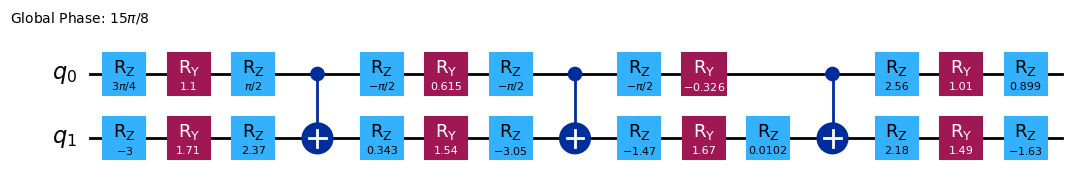

In [17]:
# Standard decomposition
standard_circuit = unitary2circuit(Ub1)
print(f"Standard Circuit Depth: {standard_circuit.depth()}")
print(f"CNOT Count: {standard_circuit.count_ops().get('cx', 0)}")
standard_circuit.draw('mpl', reverse_bits=False)

# 5. General POVM Optimization (2 CNOTs)
This allows implementation with 2 CNOTs.

Optimized (General) Circuit CNOT Count: 2


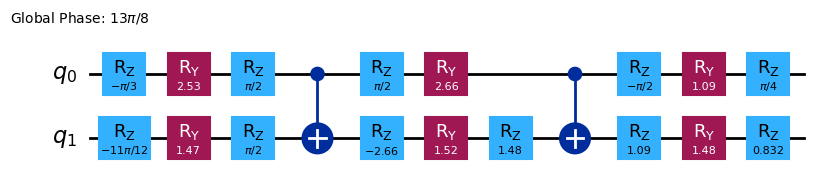

In [18]:
from scipy.optimize import brute, brentq

# Objective function: Minimize |z| component of KAK interaction
def interaction_strength_abs(gamma2):
    # Construct controlled-U3 gate
    control_op = controlled_U3_pauli(0, gamma2, 0)
    # Calculate KAK coordinates of U_SIC * Control_Op
    _, _, z = kak_decomposition(Ub1 @ control_op)
    return np.abs(z)

# Signed interaction strength for root finding
def interaction_strength_signed(gamma2):
    control_op = controlled_U3_pauli(0, gamma2, 0)
    _, _, z = kak_decomposition(Ub1 @ control_op)
    return z 

# 1. Coarse Search
search_range = (0, 1 * np.pi)
gamma2_approx = brute(interaction_strength_abs, [search_range], Ns=1000, full_output=False, finish=None)

# 2. Fine Tuning (Root Finding)
gamma2_opt = brentq(interaction_strength_signed, gamma2_approx - np.pi/100, gamma2_approx + np.pi/100, xtol=1e-30)

# Construct Optimized Unitary
optimized_control_op = controlled_U3_pauli(0, gamma2_opt, 0)
U_opt_2cnot = Ub1 @ optimized_control_op

# Visualize 2-CNOT Circuit
circuit_2cnot = unitary2circuit(U_opt_2cnot)
print(f"Optimized (General) Circuit CNOT Count: {circuit_2cnot.count_ops().get('cx', 0)}")
circuit_2cnot.draw('mpl', reverse_bits=False)

In [19]:
np.isclose(U_opt_2cnot, Ub1)

array([[ True,  True, False, False],
       [ True,  True, False, False],
       [ True,  True, False, False],
       [ True,  True, False, False]])

# 6. Define Reference SIC-POVM (Case 2: Bell Measurement)
Construct the reference unitary $U_{\mathrm{SIC}-2}$, which corresponds to a Bell measurement circuit (1 CNOT).
This serves as the target for our transformation.

In [20]:
# Construct U_SIC-2 (Bell Measurement Circuit)
qc_ref = QuantumCircuit(2)
qc_ref.rx(np.arccos(1/np.sqrt(3)), 1) # Rotate to fiducial state
qc_ref.rz(3 * np.pi / 4, 1)
qc_ref.cx(1, 0)                       # Bell basis measurement
qc_ref.h(1)
Ub2 = Operator(qc_ref).data

print("U_SIC-2 (Reference) Matrix initialized.")

U_SIC-2 (Reference) Matrix initialized.


# 7. Calculate Transformation Parameters (S4 Method)
We aim to find parameters $\{U_S, \vec{\beta}, c\}$ such that $U_{\mathrm{SIC}-1}$ can be transformed into $U_{\mathrm{SIC}-2}$.

Key equation: $U_{\mathrm{SIC}-1} \approx U_{perm} \cdot U_{phase} \cdot U_{\mathrm{SIC}-2} \cdot (I \otimes U_S)$

In [21]:
# 1. Extract Parameters (U_S, phases, relabeling_flag)
u_s, phases, requires_cnot = get_sic_parameters(Ub1)

print(f"Requires Relabeling (CNOT at end): {requires_cnot}")
print(f"Phases (beta1, beta2, beta3): {phases}")

# 2. Construct Component Matrices
# Phase correction matrix (Diagonal)
# Note: CZtheta and ZZtheta are custom helpers, ensure they are defined/imported
U_phase = CZtheta(phases[2]) @ ZZtheta(phases[0], phases[1])

# Permutation matrix (Relabeling)
U_perm = np.eye(4) # Identity
if requires_cnot:
    # CNOT matrix (assuming Cnot1 corresponds to standard CNOT)
    U_perm = np.array([[1,0,0,0],[0,1,0,0],[0,0,0,1],[0,0,1,0]]) 

# 3. Verify Transformation
# We check if U_SIC-2 is equivalent to the transformed U_SIC-1
# U_SIC-2 ~ (U_phase^-1 * U_perm * U_SIC-1 * (I tensor U_S)^-1)
U_s_expanded = np.kron(np.eye(2), u_s)
U_transformed = np.linalg.inv(U_phase) @ U_perm @ Ub1 @ np.linalg.inv(U_s_expanded)

print(f"Transformation Verification (U_target == U_ref): \n{np.isclose(Ub2, U_transformed)}")

# 4. Reverse Verification
# Reconstruct U_SIC-1 from U_SIC-2 and parameters
Ub1_reconstructed = U_perm @ U_phase @ Ub2 @ U_s_expanded
print(f"Reconstruction Verification (U_source == U_rec):\n{np.isclose(Ub1, Ub1_reconstructed)}")

Requires Relabeling (CNOT at end): False
Phases (beta1, beta2, beta3): (3.502421173506021e-16, 4.711188298628549e-17, 1.570796326794896)
Transformation Verification (U_target == U_ref): 
[[ True  True False False]
 [ True  True False False]
 [ True  True False False]
 [ True  True False False]]
Reconstruction Verification (U_source == U_rec):
[[ True  True False False]
 [ True  True False False]
 [ True  True False False]
 [ True  True False False]]


# 8. Handling the Orthogonal Complement (W Matrix)
The SIC-POVM is defined by the first two columns ($V$). The last two columns ($W$) can be adjusted freely.
We calculate the unitary $Q$ that maps the $W$ subspace of the reference to the target.

In [22]:
# Extract W matrices (last 2 columns)
W1 = Ub1[:, 2:]
W2_base = Ub2[:, 2:]

# Apply transformations to reference W
W2_transformed = U_perm @ U_phase @ W2_base @ u_s

# Calculate Q = W2_transformed^+ * W1
# Q represents the rotation within the ancillary subspace
Q_matrix = np.linalg.pinv(W2_transformed) @ W1

# Verify W1 = W2_transformed * Q
print(f"Q Matrix Validity: \n{np.isclose(W2_transformed @ Q_matrix, W1)}")

Q Matrix Validity: 
[[ True  True]
 [ True  True]
 [ True  True]
 [ True  True]]


# 9. Circuit Implementation of Q
Verify if the calculated $Q$ matrix matches a known controlled-unitary operation (e.g., Controlled-U3).
This ensures the full $4 \times 4$ unitary is implementable.

In [23]:
# Full check: U_SIC-1 reconstruction with Q
# Construct full 4x4 control-Q operation
Control_Q_Full = np.block([
    [np.eye(2), np.zeros((2, 2))], 
    [np.zeros((2, 2)), Q_matrix]
])

# Full reconstruction chain
# Ub1 ~ U_perm * U_phase * U_SIC-2 * (I tensor U_S) * Control_Q
Ub1_full_rec = U_perm @ U_phase @ Ub2 @ U_s_expanded @ Control_Q_Full

print(f"Full Unitary Reconstruction Verification:\n {np.isclose(Ub1_full_rec, Ub1)}")

Full Unitary Reconstruction Verification:
 [[ True  True  True  True]
 [ True  True  True  True]
 [ True  True  True  True]
 [ True  True  True  True]]


# 10. Visualization of Weyl Chamber Trajectories
Explore how varying the control gate parameters affects the position in the Weyl Chamber (KAK decomposition).
This visualizes the optimization landscape.

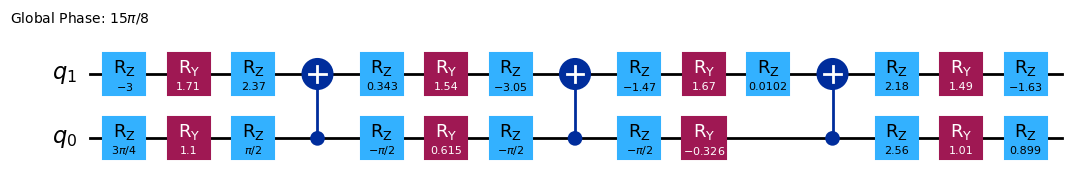

In [24]:
ucirc = unitary2circuit(Ub1)
ucirc.draw(output='mpl',reverse_bits=True)

In [25]:
points = []
for theta in np.linspace(0, np.pi, 5):
    for phi in np.linspace(0, 2*np.pi, 10):
        for lambda_ in np.linspace(0, 2*np.pi, 10):
            CQ = controlled_U3(theta, phi, lambda_)
            x, y, z = kak_decomposition(np.linalg.inv(U_phase)@U_perm@Ub1@np.linalg.inv(np.kron(np.eye(2),u_s)) @ CQ )
            points.append((x, y, z))
plt = interactive_plot(points,0,0)
plt

interactive(children=(IntSlider(value=0, description='x_rotation', max=360), IntSlider(value=0, description='y…

In [26]:
points = []
for theta in np.linspace(0, np.pi, 5):
    for phi in np.linspace(0, 2*np.pi, 10):
        for lambda_ in np.linspace(0, 2*np.pi, 10):
            CQ = controlled_U3(theta, phi, lambda_)
            x, y, z = kak_decomposition(Ub1@ CQ )
            points.append((x, y, z))
plt1 = interactive_plot(points,0,0)
plt1

interactive(children=(IntSlider(value=0, description='x_rotation', max=360), IntSlider(value=0, description='y…